# Job Salary Prediction
Predicting annual salary from job title, experience, education, company size, location and other features using Linear Regression, Decision Tree and Random Forest (scikit-learn).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

def salary_formatter(x, pos):
    return f'${x/1000:,.0f}K'


In [3]:
df=pd.read_csv('job_salary_prediction_dataset.csv')
# keep an unencoded copy for the salary-by-category charts
df_original = df.copy()


In [4]:
df

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467


## 1. Exploratory Data Analysis

In [5]:
print("the statistical summary:")
df.describe()

the statical summary:


,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


In [6]:
print("Dataset Info:")
print(df.info())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB
None


In [7]:
print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

Duplicate Rows: 0


In [8]:
print("Unique values per column:")
for col in df.columns:
    print(f"  {col}: {df[col].nunique()} unique → {df[col].unique()[:5]}")

Unique values per column:
  job_title: 12 unique → ['AI Engineer' 'Data Analyst' 'Frontend Developer' 'Business Analyst'
 'Product Manager']
  experience_years: 21 unique → [10  5 18 19 15]
  education_level: 5 unique → ['Bachelor' 'PhD' 'High School' 'Diploma' 'Master']
  skills_count: 19 unique → [ 2 17  4 13  7]
  industry: 10 unique → ['Healthcare' 'Telecom' 'Media' 'Retail' 'Manufacturing']
  company_size: 5 unique → ['Medium' 'Small' 'Large' 'Enterprise' 'Startup']
  location: 10 unique → ['India' 'Australia' 'Singapore' 'Canada' 'Sweden']
  remote_work: 3 unique → ['Hybrid' 'No' 'Yes']
  certifications: 6 unique → [2 0 1 3 5]
  salary: 118956 unique → [109413  93764 148123 189123 165069]


## 2. Preprocessing
Label-encode categorical columns, scale features, and split 80/20 into train/test.

In [9]:
le = LabelEncoder()
categorical_cols = ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']
# changing all typing to numeric
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])
print("After Label Encoding:")
df.head()

After Label Encoding:


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,0,10,0,2,4,2,3,0,2,109413
1,5,5,0,17,9,3,0,1,0,93764
2,8,18,4,4,6,2,6,1,1,148123
3,2,19,4,13,7,2,1,2,0,189123
4,10,15,0,7,5,1,7,2,0,165069


In [10]:
#feature selection
X=df.drop(columns=['salary'])
Y=df['salary']

In [11]:
print("X shape:", X.shape)
print("y shape:", Y.shape)
print("\nFeatures used:")
print(X.columns.tolist())

X shape: (250000, 9)
y shape: (250000,)

Features used:
['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications']


In [12]:
#StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Before Scaling - experience_years sample:")
print(df['experience_years'].head())
print("\nAfter Scaling - experience_years sample:")
print(X_scaled[:5, 1])

Before Scaling - experience_years sample:
0    10
1     5
2    18
3    19
4    15
Name: experience_years, dtype: int64

After Scaling - experience_years sample:
[-8.92322321e-04 -8.25894468e-01  1.31911111e+00  1.48411154e+00
  8.24109823e-01]


In [13]:
#testing and training 
X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y,test_size=0.2,random_state=42)
#for explaining 
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (200000, 9)
X_test shape: (50000, 9)
y_train shape: (200000,)
y_test shape: (50000,)


## 3. Model Training

In [14]:
#Linear regression model:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print("✅ Linear Regression Done!")

✅ Linear Regression Done!


In [15]:
# Decision tree model
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("✅ Decision Tree Done!")

✅ Decision Tree Done!


In [16]:
#Random forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)##100 trees
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("✅ Random Forest Done!")

✅ Random Forest Done!


## 4. Evaluation
5-fold cross-validation and test-set metrics (MAE, RMSE, R²).

In [17]:
#cross val
# Linear Regression
lr_cv = cross_val_score(lr_model, X_scaled, Y, cv=5, scoring='r2')
print(f"Linear Regression CV R²: {lr_cv.mean():.4f} ± {lr_cv.std():.4f}")

# Decision Tree
dt_cv = cross_val_score(dt_model, X_scaled, Y, cv=5, scoring='r2')
print(f"Decision Tree CV R²:     {dt_cv.mean():.4f} ± {dt_cv.std():.4f}")

# Random Forest
rf_cv = cross_val_score(rf_model, X_scaled, Y, cv=5, scoring='r2')
print(f"Random Forest CV R²:     {rf_cv.mean():.4f} ± {rf_cv.std():.4f}")

Linear Regression CV R²: 0.4587 ± 0.0045
Decision Tree CV R²:     0.9320 ± 0.0002
Random Forest CV R²:     0.9693 ± 0.0001


In [29]:
def evaluate_model(name, y_test, y_pred):
    mae  = mean_absolute_error(y_test, y_pred)
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test, y_pred)
    print(f"\n📊 {name}")
    print(f"  MAE  : ${mae:,.2f}")
    print(f"  MSE  : ${mse:,.2f}")
    print(f"  RMSE : ${rmse:,.2f}")
    print(f"  R²   : {r2:.4f}")
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2}\

results = []
results.append(evaluate_model("Linear Regression", y_test, lr_pred))
results.append(evaluate_model("Decision Tree",     y_test, dt_pred))
results.append(evaluate_model("Random Forest",     y_test, rf_pred))
results_df = pd.DataFrame(results)
print("\n\n📋 Comparison Table:")
print(results_df.to_string(index=False))


📊 Linear Regression
  MAE  : $21,740.62
  MSE  : $756,119,410.27
  RMSE : $27,497.63
  R²   : 0.4560

📊 Decision Tree
  MAE  : $7,597.27
  MSE  : $95,656,271.54
  RMSE : $9,780.40
  R²   : 0.9312

📊 Random Forest
  MAE  : $5,183.69
  MSE  : $42,999,954.07
  RMSE : $6,557.44
  R²   : 0.9691


📋 Comparison Table:
            Model          MAE          MSE         RMSE       R²
Linear Regression 21740.623781 7.561194e+08 27497.625539 0.455976
    Decision Tree  7597.272940 9.565627e+07  9780.402422 0.931176
    Random Forest  5183.690682 4.299995e+07  6557.435022 0.969062


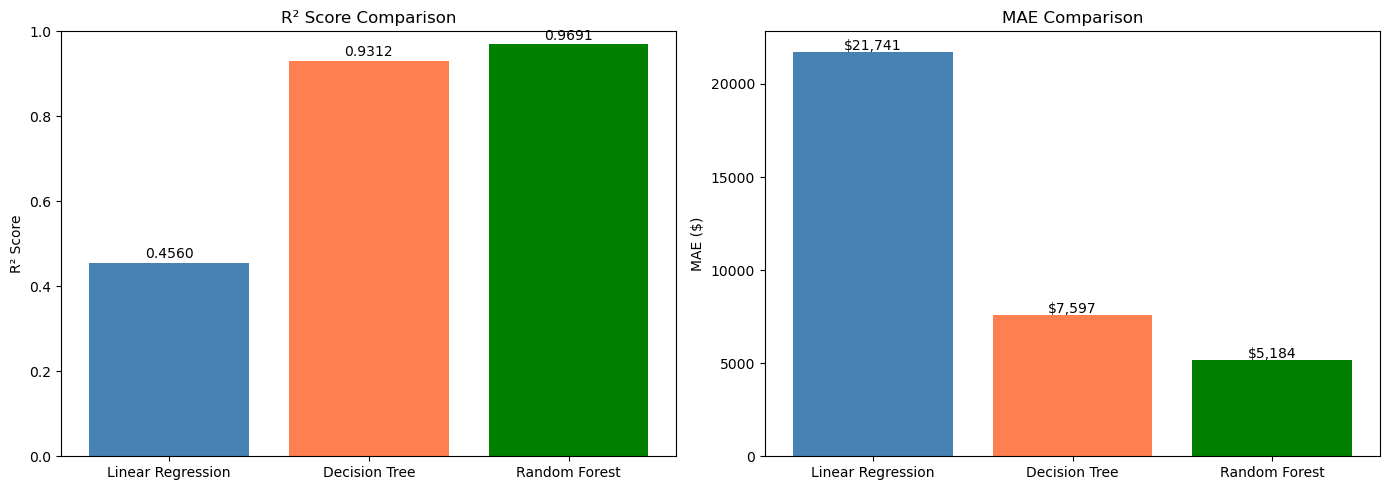

In [103]:
#Model Comparison

models = ['Linear Regression', 'Decision Tree', 'Random Forest']
r2_scores = [results[0]['R²'], results[1]['R²'], results[2]['R²']]
mae_scores = [results[0]['MAE'], results[1]['MAE'], results[2]['MAE']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² Comparison
axes[0].bar(models, r2_scores, color=['steelblue', 'coral', 'green'])
axes[0].set_title('R² Score Comparison')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1)
for i, v in enumerate(r2_scores):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center')

# MAE Comparison
axes[1].bar(models, mae_scores, color=['steelblue', 'coral', 'green'])
axes[1].set_title('MAE Comparison')
axes[1].set_ylabel('MAE ($)')
for i, v in enumerate(mae_scores):
    axes[1].text(i, v + 100, f'${v:,.0f}', ha='center')

plt.tight_layout()
plt.show()

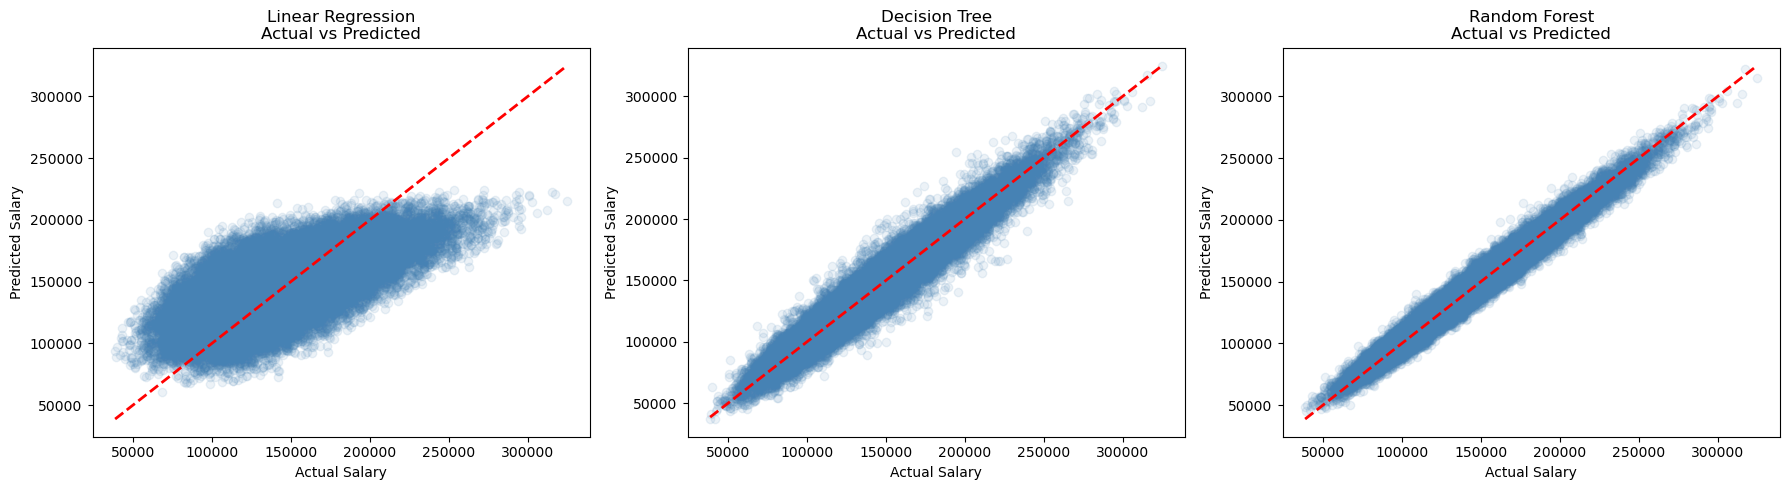

In [104]:
#Actual vs Predicted

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
preds = [lr_pred, dt_pred, rf_pred]

for i, (name, pred) in enumerate(zip(models, preds)):
    axes[i].scatter(y_test, pred, alpha=0.1, color='steelblue')
    axes[i].plot([y_test.min(), y_test.max()],
                 [y_test.min(), y_test.max()],
                 'r--', linewidth=2)
    axes[i].set_title(f'{name}\nActual vs Predicted')
    axes[i].set_xlabel('Actual Salary')
    axes[i].set_ylabel('Predicted Salary')

plt.tight_layout()
plt.show()

## 5. Feature Importance & Salary Insights

In [105]:
# Feature Importance Scores
#random forest يحسب القيم
importance_df = pd.DataFrame({'Feature':    X.columns.tolist(),'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)
importance_df['Importance %'] = (importance_df['Importance'] * 100).round(2).astype(str) + '%'
print(importance_df.to_string(index=False))

         Feature  Importance Importance %
        location    0.329262       32.93%
experience_years    0.198557       19.86%
    company_size    0.168726       16.87%
       job_title    0.158214       15.82%
 education_level    0.097679        9.77%
    skills_count    0.025440        2.54%
  certifications    0.009609        0.96%
        industry    0.006924        0.69%
     remote_work    0.005590        0.56%


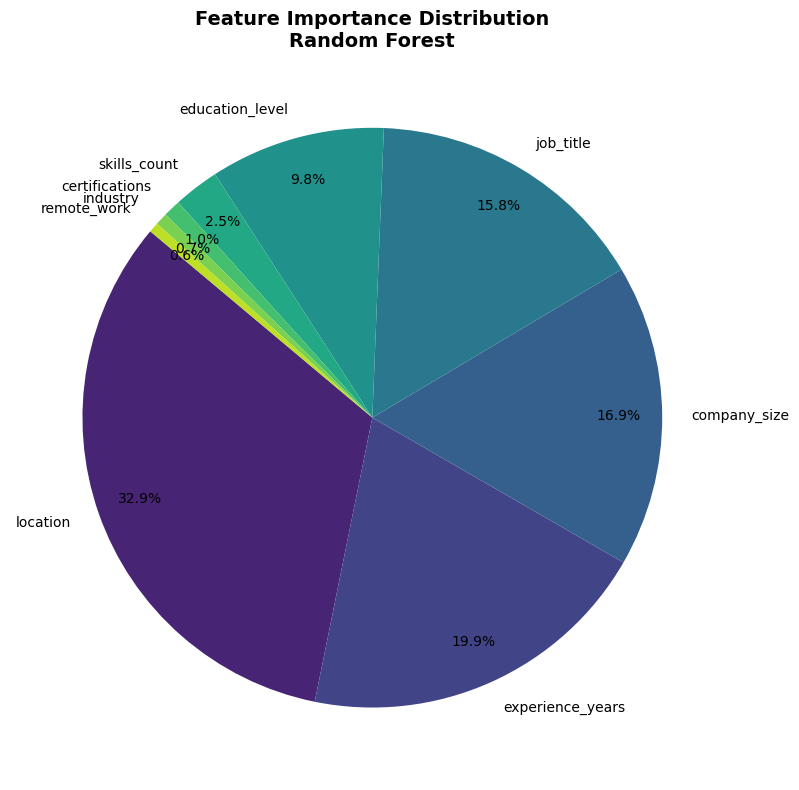

In [107]:
importance_df = pd.DataFrame({'Feature':    X.columns.tolist(),'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)
plt.figure(figsize=(10, 8))
plt.pie(importance_df['Importance'],labels=importance_df['Feature'],autopct='%1.1f%%',colors=sns.color_palette('viridis', len(importance_df)),startangle=140,pctdistance=0.85)
plt.title('Feature Importance Distribution\nRandom Forest',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

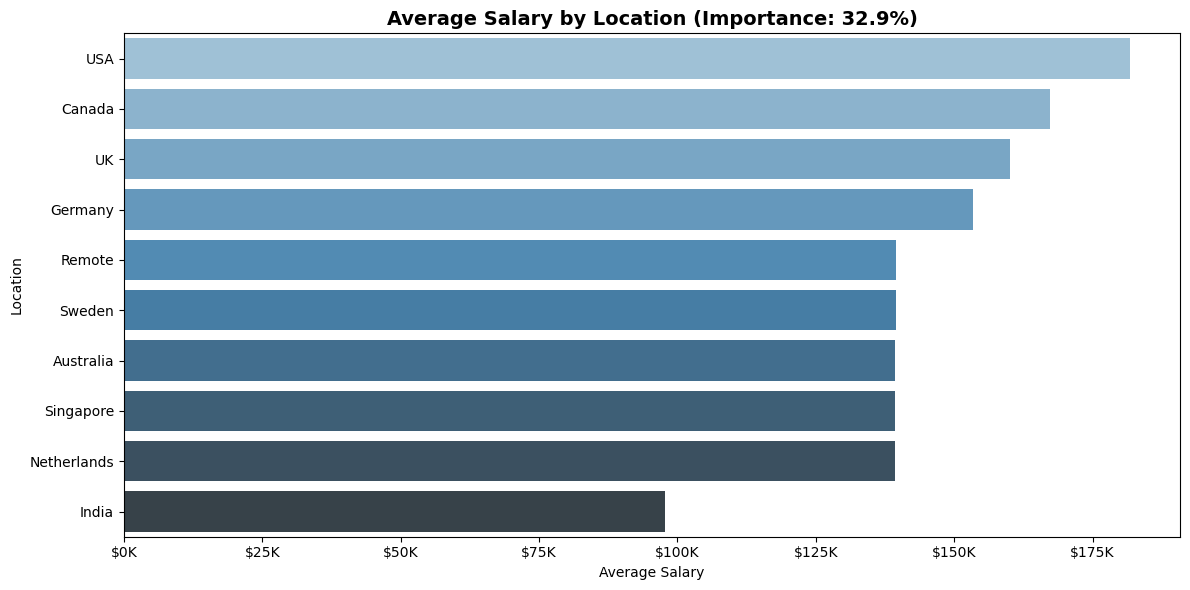

In [119]:
plt.figure(figsize=(12, 6))
loc_salary = df_original.groupby('location')['salary'].mean().sort_values(ascending=False)
ax = sns.barplot(x=loc_salary.values, y=loc_salary.index, palette='Blues_d',hue=loc_salary.index, legend=False)
ax.xaxis.set_major_formatter(FuncFormatter(salary_formatter))
plt.title('Average Salary by Location (Importance: 32.9%)', fontsize=14, fontweight='bold')
plt.xlabel('Average Salary')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

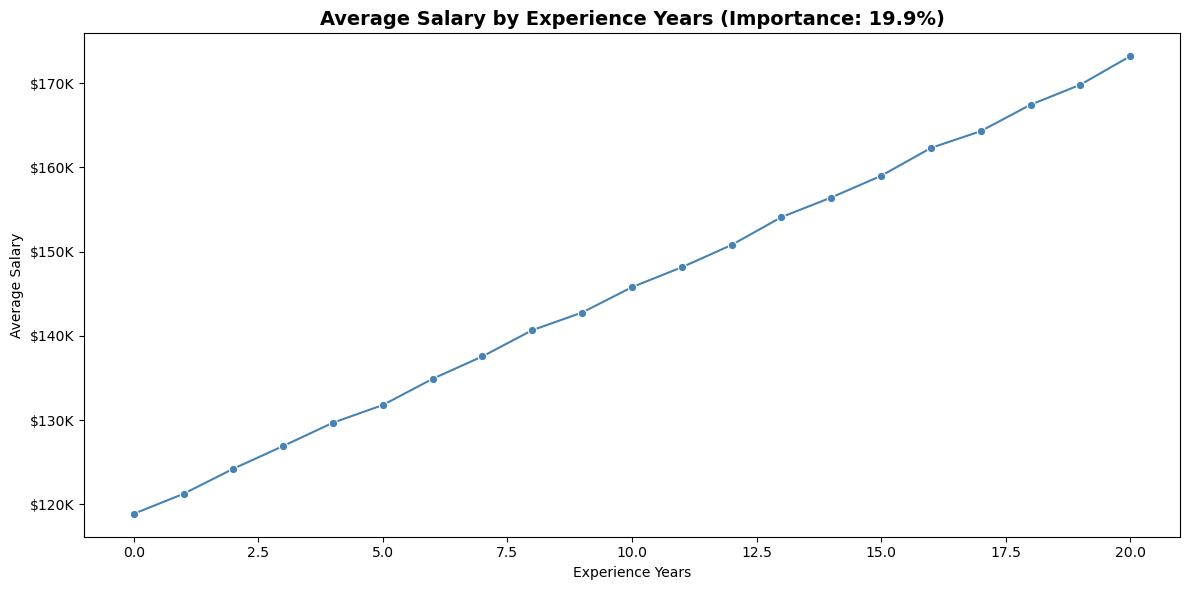

In [115]:
plt.figure(figsize=(12, 6))
exp_salary = df_original.groupby('experience_years')['salary'].mean()
ax = sns.lineplot(x=exp_salary.index, y=exp_salary.values,color='steelblue', marker='o')
ax.yaxis.set_major_formatter(FuncFormatter(salary_formatter))
plt.title('Average Salary by Experience Years (Importance: 19.9%)',fontsize=14, fontweight='bold')
plt.xlabel('Experience Years')
plt.ylabel('Average Salary')
plt.tight_layout()
plt.show()

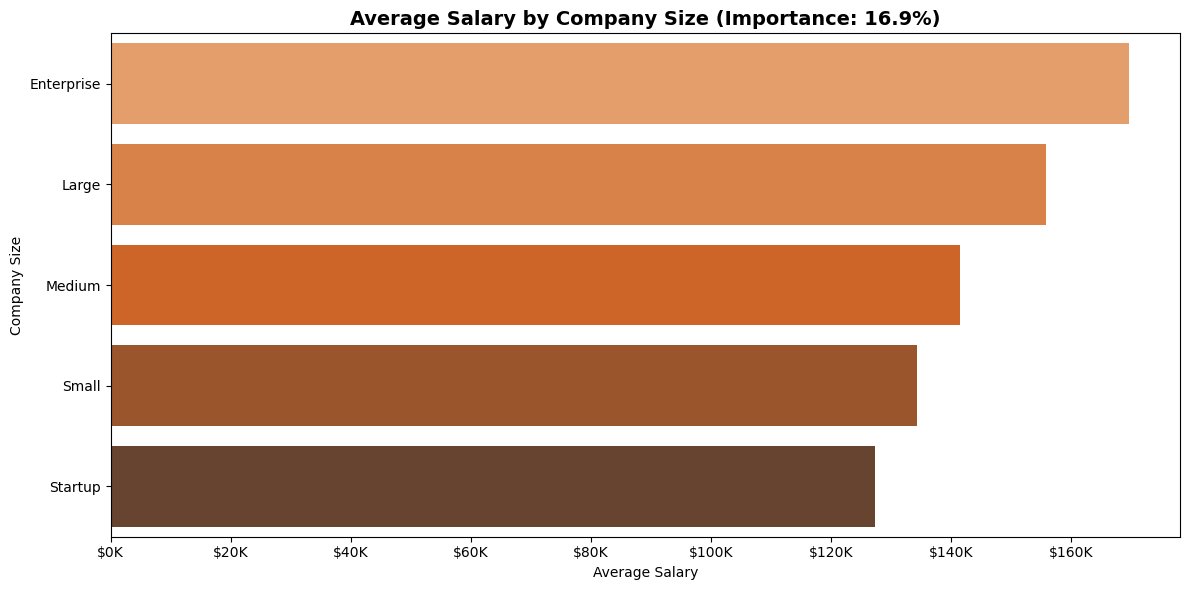

In [120]:
plt.figure(figsize=(12, 6))
comp_salary = df_original.groupby('company_size')['salary'].mean().sort_values(ascending=False)
ax = sns.barplot(x=comp_salary.values, y=comp_salary.index, palette='Oranges_d',hue=comp_salary.index, legend=False)
ax.xaxis.set_major_formatter(FuncFormatter(salary_formatter))
plt.title('Average Salary by Company Size (Importance: 16.9%)',fontsize=14, fontweight='bold')
plt.xlabel('Average Salary')
plt.ylabel('Company Size')
plt.tight_layout()
plt.show()

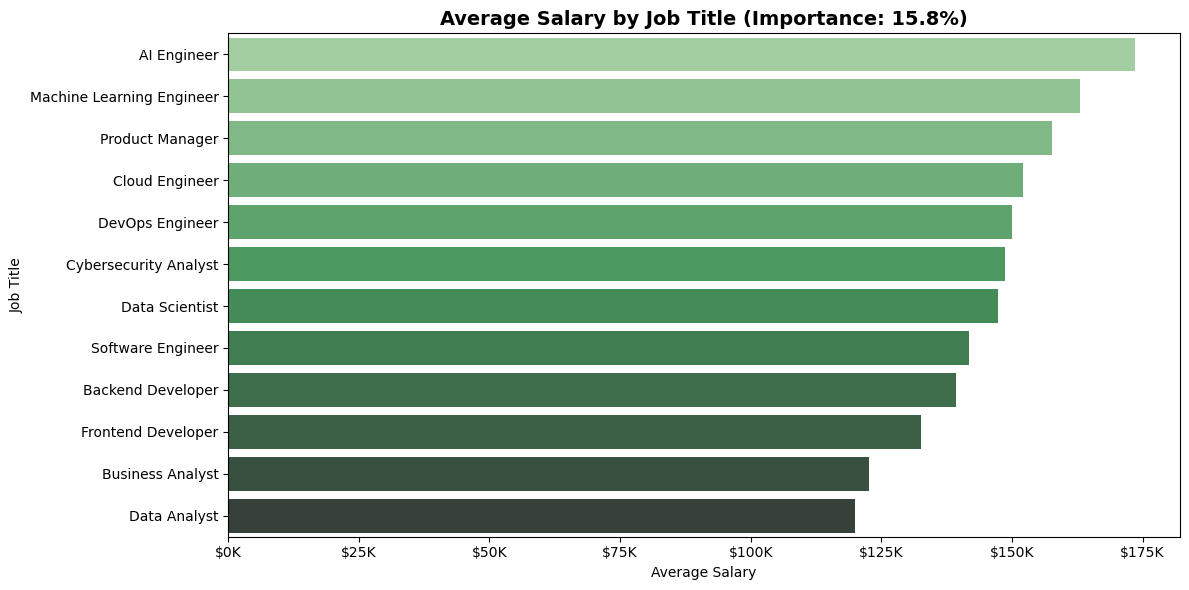

In [121]:
plt.figure(figsize=(12, 6))
job_salary = df_original.groupby('job_title')['salary'].mean().sort_values(ascending=False)
ax = sns.barplot(x=job_salary.values, y=job_salary.index, palette='Greens_d',hue=job_salary.index, legend=False)
ax.xaxis.set_major_formatter(FuncFormatter(salary_formatter))
plt.title('Average Salary by Job Title (Importance: 15.8%)',fontsize=14, fontweight='bold')
plt.xlabel('Average Salary')
plt.ylabel('Job Title')
plt.tight_layout()
plt.show()

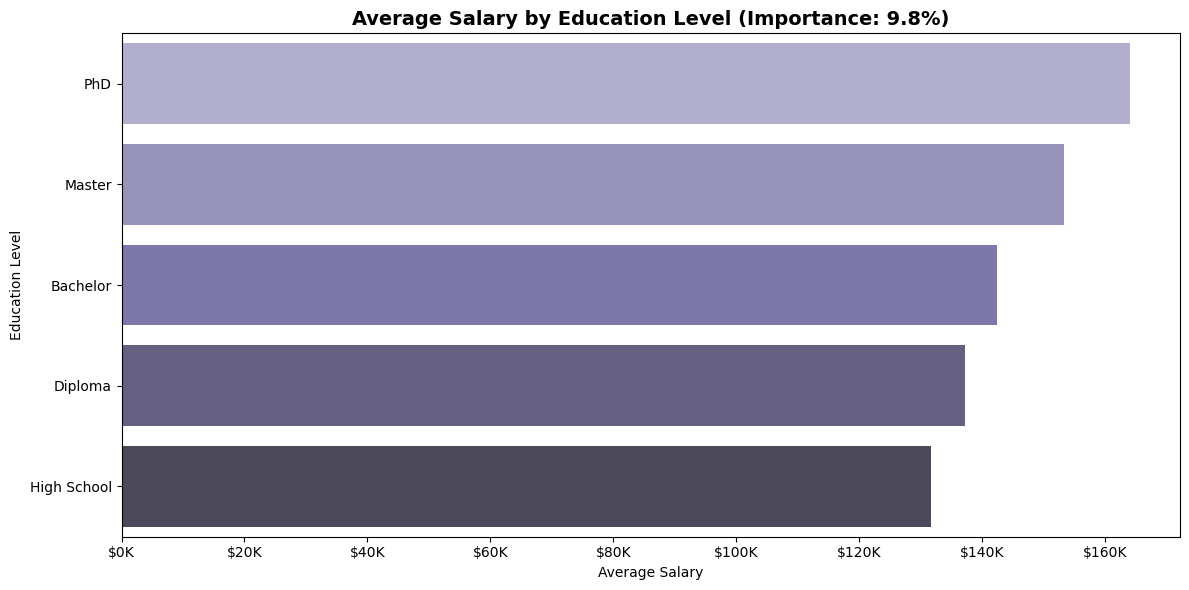

In [122]:
plt.figure(figsize=(12, 6))
edu_salary = df_original.groupby('education_level')['salary'].mean().sort_values(ascending=False)
ax = sns.barplot(x=edu_salary.values, y=edu_salary.index, palette='Purples_d',hue=edu_salary.index, legend=False)
ax.xaxis.set_major_formatter(FuncFormatter(salary_formatter))
plt.title('Average Salary by Education Level (Importance: 9.8%)',fontsize=14, fontweight='bold')
plt.xlabel('Average Salary')
plt.ylabel('Education Level')
plt.tight_layout()
plt.show()